<a href="https://colab.research.google.com/github/LilanthaWeerakkodi/Hello-World/blob/main/Lab4_Learning_Paradigms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score

In [2]:
iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df['target'] = y

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
print(df.head())

print("\nClass names:")
print(iris.target_names)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (150, 5)

First 5 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  

Class names:
['setosa' 'versicolor' 'virginica']

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
lr = LogisticRegression(max_iter=200)

lr.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=200)

In [7]:
lr_pred = lr.predict(X_test_scaled)

lr_accuracy = accuracy_score(y_test, lr_pred)

print("Logistic Regression Accuracy:",
      lr_accuracy * 100, "%")

Logistic Regression Accuracy: 93.33333333333333 %


In [8]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(
    StandardScaler().fit_transform(X)
)

print("Cluster labels:")
print(kmeans_labels)

Cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


In [9]:
for cluster in range(3):

    actual_labels = y[kmeans_labels == cluster]

    counts = np.bincount(actual_labels, minlength=3)

    purity = counts.max() / len(actual_labels)

    print("Cluster:", cluster)
    print("Flower counts:", counts)
    print("Cluster purity:", round(purity * 100, 2), "%")
    print()

Cluster: 0
Flower counts: [ 0 39 14]
Cluster purity: 73.58 %

Cluster: 1
Flower counts: [50  0  0]
Cluster purity: 100.0 %

Cluster: 2
Flower counts: [ 0 11 36]
Cluster purity: 76.6 %



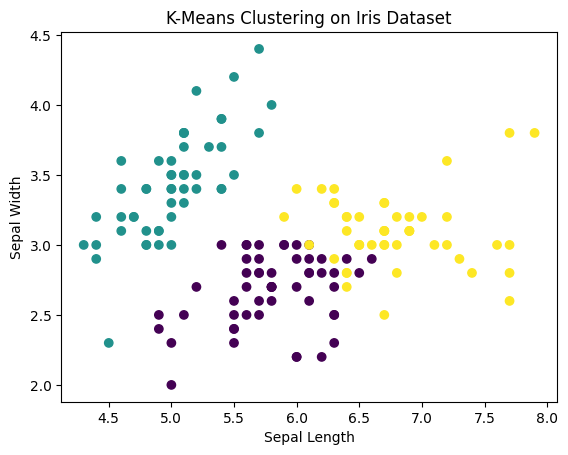

In [10]:
plt.scatter(
    X[:, 0],
    X[:, 1],
    c=kmeans_labels
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("K-Means Clustering on Iris Dataset")

plt.show()

In [11]:
k_values = [1, 3, 5]
knn_accuracies = []
knn_models = {}

for k in k_values:

    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train_scaled, y_train)

    prediction = knn.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, prediction)

    knn_accuracies.append(accuracy)

    knn_models[k] = knn

    print("K =", k)
    print("Accuracy =", accuracy * 100, "%")
    print()

K = 1
Accuracy = 96.66666666666667 %

K = 3
Accuracy = 93.33333333333333 %

K = 5
Accuracy = 93.33333333333333 %



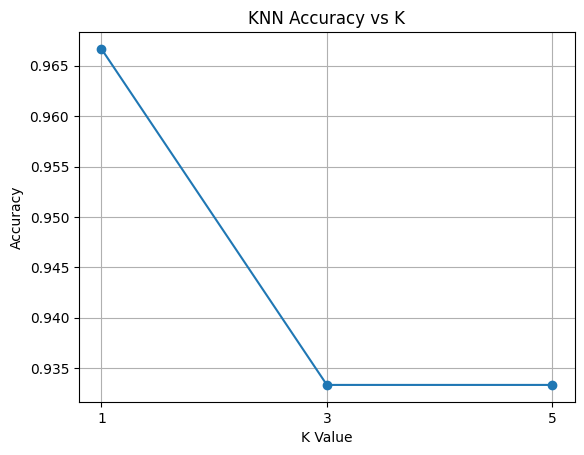

In [12]:
plt.plot(
    k_values,
    knn_accuracies,
    marker='o'
)

plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy vs K")

plt.xticks(k_values)
plt.grid()

plt.show()

In [13]:
# Use KNN with k=3
knn = knn_models[3]

# Number of repeated predictions
repeats = 1000

# Measure Logistic Regression prediction time
start = time.perf_counter()

for i in range(repeats):
    lr.predict(X_test_scaled)

lr_time = time.perf_counter() - start


# Measure KNN prediction time
start = time.perf_counter()

for i in range(repeats):
    knn.predict(X_test_scaled)

knn_time = time.perf_counter() - start


print("Logistic Regression total time:",
      lr_time, "seconds")

print("KNN total time:",
      knn_time, "seconds")

print("\nLogistic Regression average time:",
      lr_time / repeats, "seconds")

print("KNN average time:",
      knn_time / repeats, "seconds")

Logistic Regression total time: 0.3322314910000159 seconds
KNN total time: 2.929849364000006 seconds

Logistic Regression average time: 0.0003322314910000159 seconds
KNN average time: 0.002929849364000006 seconds


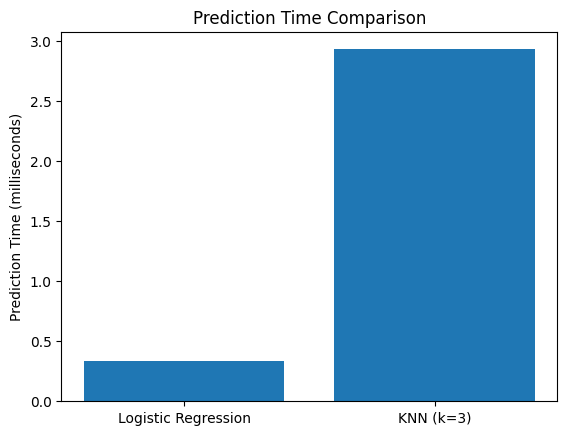

In [14]:
models = ['Logistic Regression', 'KNN (k=3)']

times = [
    lr_time / repeats * 1000,
    knn_time / repeats * 1000
]

plt.bar(models, times)

plt.ylabel("Prediction Time (milliseconds)")
plt.title("Prediction Time Comparison")

plt.show()

In [15]:
results = pd.DataFrame({
    'Learning Method': [
        'Logistic Regression',
        'KNN (k=1)',
        'KNN (k=3)',
        'KNN (k=5)'
    ],
    'Accuracy (%)': [
        lr_accuracy * 100,
        knn_accuracies[0] * 100,
        knn_accuracies[1] * 100,
        knn_accuracies[2] * 100
    ]
})

print(results)

       Learning Method  Accuracy (%)
0  Logistic Regression     93.333333
1            KNN (k=1)     96.666667
2            KNN (k=3)     93.333333
3            KNN (k=5)     93.333333
